# Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective:** Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset:** This lab utilizes the Amazon UK product dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

### Part 0: Set Up

#### 0.1 Import Libraries

In [2]:
# Importing the Seaborn library for advanced data visualization (as sns)
import seaborn as sns

# Importing the Matplotlib library for basic plotting functionalities (as plt)
import matplotlib.pyplot as plt

# Importing the Pandas library for data manipulation and analysis (as pd)
import pandas as pd

# Importing the NumPy library for numerical operations (as np)
import numpy as np

#### 0.2 Set Plot Design

In [3]:
# Matplotlib inline to visualize Matplotlib graphs
%matplotlib inline

# Configuration to set so that all the Seaborn figures come out with this size
%config Inlinebackend.figure_format= 'retina'

# Set the Seaborn context to "poster" for larger text and figures
sns.set_context("poster")

# Set the default figure size for Seaborn plots
sns.set(rc={"figure.figsize": (12., 6.)})

# Set the Seaborn style to "whitegrid" for a white background with gridlines
sns.set_style("whitegrid")

#### 0.3 Load & Understand Data

In [4]:
%pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Note: you may need to restart the kernel to use updated packages.
Path to dataset files: C:\Users\black\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [ ]:
# read dataset

df = pd.read_csv(r"C:\Users\black\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3\amz_uk_price_prediction_dataset.csv")

df.head()



,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [54]:
df.tail()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing
2443650,2828593,B08P3W9B3T,RIDEX CJ223 Motorcycle Motorbike Jacket Armour...,4.5,34,53.99,False,0,Motorbike Clothing


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1.370545e+06,816056.169852,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.152836e+00,2.194865,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,4.806278e+02,5944.124151,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,8.924381e+01,345.608862,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,2.589699e+01,240.483727,0.0,0.00,0.00,0.00,50000.0


In [ ]:
# splitting dataset in numerical and categorial subsets 

num = df.select_dtypes(include="number") 
cat = df.select_dtypes(exclude="number")

In [ ]:
# missing data check

df.isnull().sum()

# no missing data 

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

## Part 1: Understanding Product Categories

**Business Question:** What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?


### 1.1 Frequency Tables:

- Generate a frequency table for the product category.
- Which are the top 5 most listed product categories?

In [ ]:
# Absolut & Relative Frequency Tables

abs_freq = cat.category.value_counts()
prop_freq = cat.category.value_counts(normalize=True).round(4)

df_freq = pd.concat([abs_freq, prop_freq], axis=1)
df_freq.columns = ['absolute_frequency', 'relative_frequency']
df_freq



,absolute_frequency,relative_frequency
category,,
Sports & Outdoors,836265,0.3422
Beauty,19312,0.0079
"Handmade Clothing, Shoes & Accessories",19229,0.0079
Bath & Body,19092,0.0078
Birthday Gifts,18978,0.0078
...,...,...
Alexa Built-In Devices,107,0.0000
Motorbike Chassis,107,0.0000
Plugs,107,0.0000


In [11]:
# Top 5 most listed products
top_5 = abs_freq.head()
prop_top_5 = prop_freq.head()

df_freq_top5 = pd.concat([top_5, prop_top_5], axis=1)
df_freq_top5.columns = ['abs_freq_top5', 'prop_freq_top5']
df_freq_top5


,abs_freq_top5,prop_freq_top5
category,,
Sports & Outdoors,836265,0.3422
Beauty,19312,0.0079
"Handmade Clothing, Shoes & Accessories",19229,0.0079
Bath & Body,19092,0.0078
Birthday Gifts,18978,0.0078


### 1.2 Visualizations:

- Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
- For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

C:\Users\black\AppData\Local\Temp\ipykernel_36012\1104629364.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


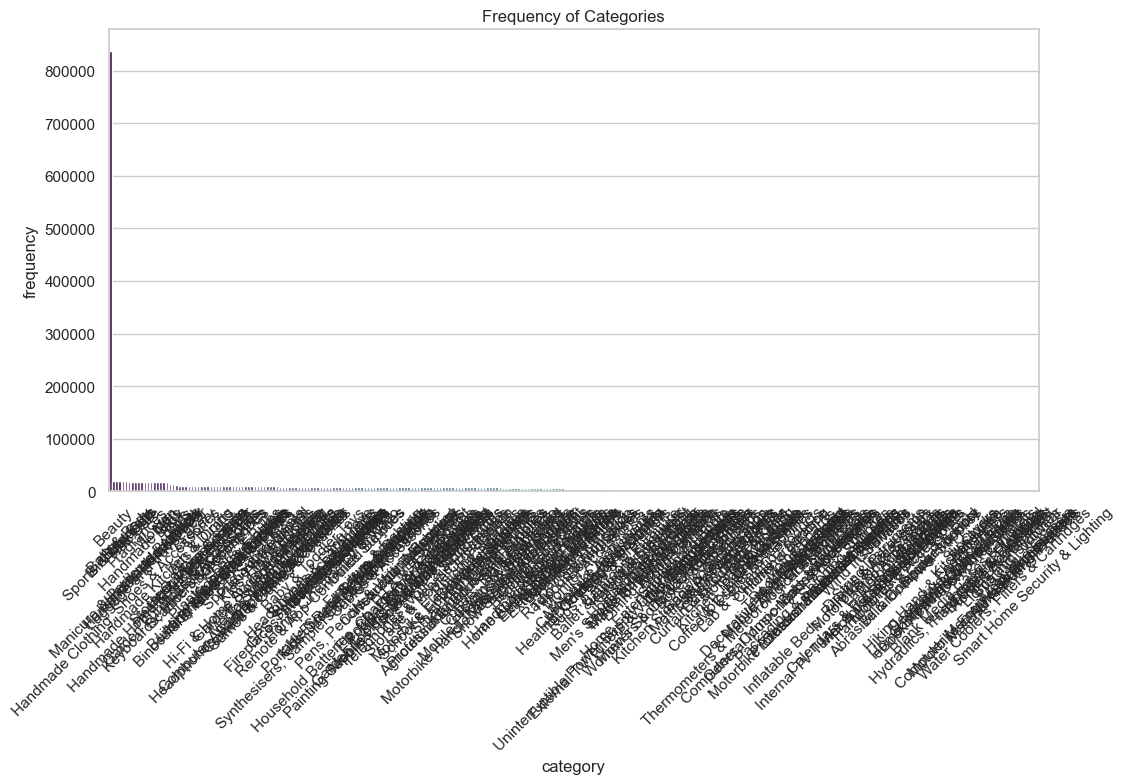

In [ ]:
# abs.freq + category to df of all data 

df_freq = abs_freq.reset_index()
df_freq.columns = ["category", "frequency"]

# creating barplot of all data

sns.barplot(
    x="category",
    y='frequency',
    data=df_freq,
    palette='viridis',
    legend=True,
)
plt.xticks(rotation=45)
plt.title("Frequency of Categories")
plt.show()

The Barplot of the whole dataset is pretty uninformative the Sports & Outdoor category owns itself ~40% of all products (out of ~300 categories) and therefore a pretty strong oulier. 
The following pie chart of the top 5 product categories will show it even clearer.

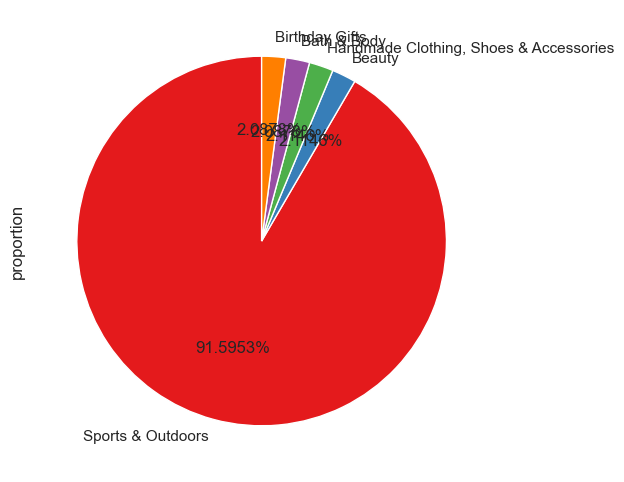

In [13]:
# pie chart top 5

prop_top_5.plot.pie(autopct='%1.4f%%' ,startangle=90, colors=sns.color_palette('Set1'))
plt.show()

**Business Answer:** 

The Sports & Outdoors product category overwhemingly dominates the marketplace, accounting for more than one-third of all products listings (296 categories). The dominance is more visible, as over it represents over 90% under the top 5 categories.

In contrast, all other categories represent less than 1% each of total listings.

Amazon UK's product landscape is heavily skewed toward Sports & Outdoors. However, smaller categories, such Handmade Clothings and Bath & Body may offer niche opportunities. 

## Part 2: Delving into Product Pricing

**Business Question:** How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

#### 2.1 Measures of Centrality:

- Calculate the mean, median, and mode for the price of products.
- What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [95]:
num.price

0          21.99
1          23.99
2          21.99
3          31.99
4          17.99
           ...  
2443646    22.34
2443647    97.99
2443648    52.99
2443649    79.99
2443650    53.99
Name: price, Length: 2443651, dtype: float64

In [14]:
# price of products: mean

num.price.mean()

89.24380943923663

In [15]:
# price of products: median

num.price.median()

19.09

In [16]:
# price of products: mode

num.price.mode()

0    9.99
Name: price, dtype: float64

In [17]:
num.price.skew()

27.492977566280338

The average price point is at ~90, whereas the most common is at ~10, so the average price is 9 times higher than from the available prices. We have a positive skewed distribution in the price.

#### 2.1 Measures of Dispersion:

- Determine the variance, standard deviation, range, and interquartile range for product price.
- How varied are the product prices? Are there any indicators of a significant spread in prices?

In [18]:
num.price.var()

119445.48532256528

In [19]:
num.price.std()

345.60886175352226

In [20]:
range = num.price.max() - num.price.min()
range

100000.0

In [21]:
iqr_range_Q10 = num.price.quantile(0.25) - num.price.min()
iqr_range_Q10

9.99

In [22]:
iqr_range_Q21 = num.price.quantile(0.5) - num.price.quantile(0.25)
iqr_range_Q21

9.1

In [23]:
iqr_range_Q32 = num.price.quantile(0.75) - num.price.quantile(0.5)
iqr_range_Q32

26.900000000000002

In [24]:
iqr_range_Q43 = num.price.quantile(1) - num.price.quantile(0.75)
iqr_range_Q43

99954.01

In [96]:
num.price.skew()

27.492977566280338

There is a very high variance on the prices. Especially, as the range spans over 100000 between lowest & highest price point. There is a strong development towards higher prices with each new quartile. The price data is heavily right-skewed.

### 2.2 Visualizations:

- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

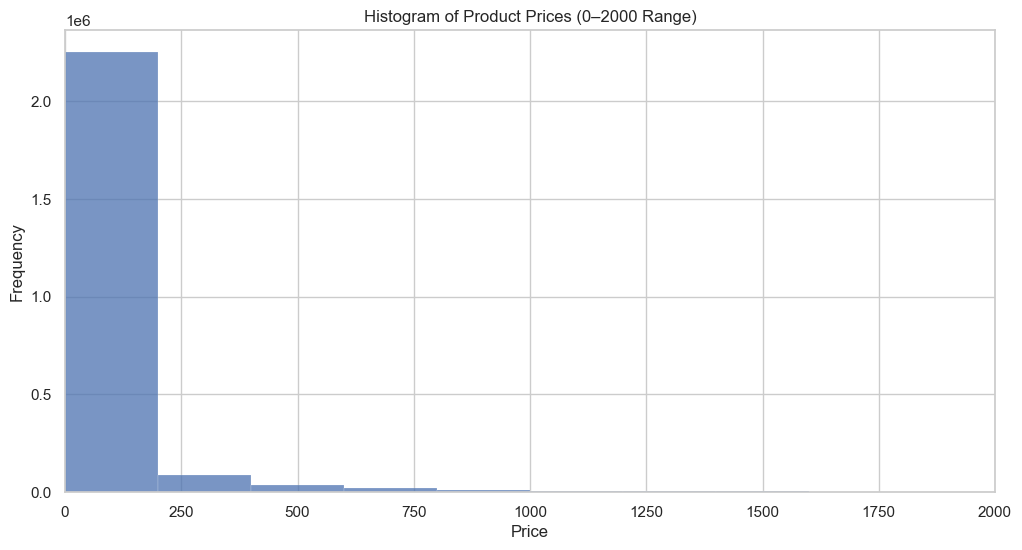

In [97]:
# histogram prices close up (0-2000 Range)

sns.histplot(num.price, bins=500)
plt.xlim(0, 2000)  
plt.title("Histogram of Product Prices (0–2000 Range)")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

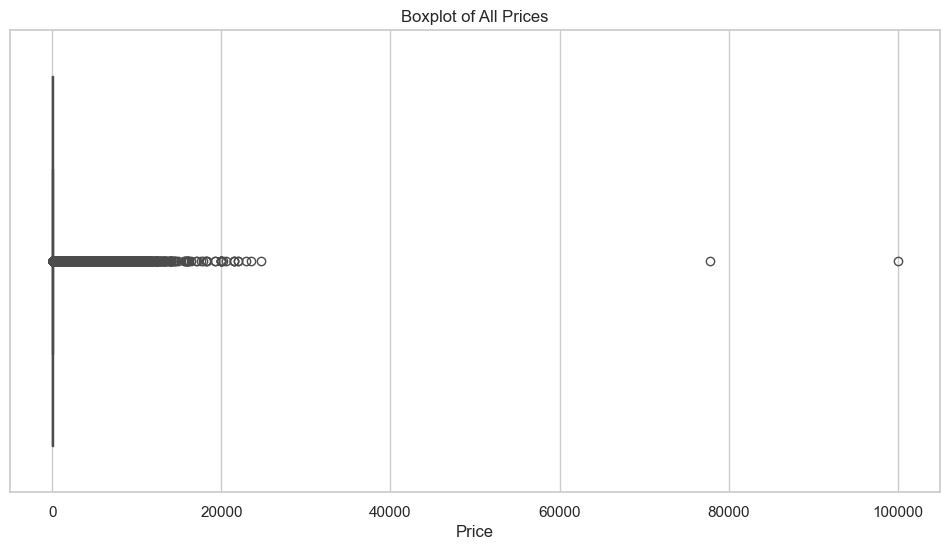

In [98]:
# Boxplot to identify outliers

sns.boxplot(x = num.price)
plt.title("Boxplot of All Prices")
plt.xlabel("Price")
plt.show

Most prices are under 500 and looking even closer and what can be read from the IQR analysis, even as low as 10, therefore all above can be treated as outliers moving forward. 

Another way is to use a log scale as it is compressing large and expanding small values.

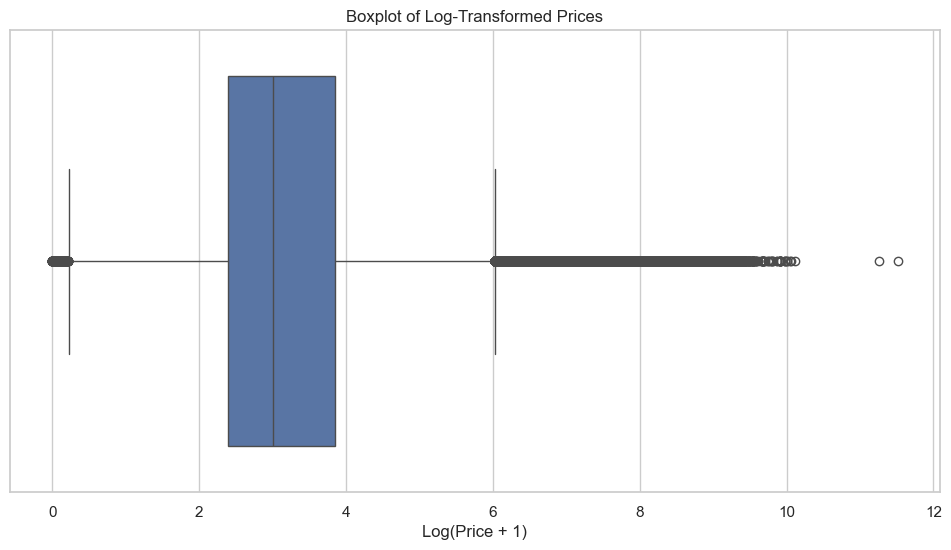

In [99]:
# log-boxplot to allow all data 

sns.boxplot(x=np.log1p(num.price))  # log1p handles zeros safely
plt.title("Boxplot of Log-Transformed Prices")
plt.xlabel("Log(Price + 1)")
plt.show()


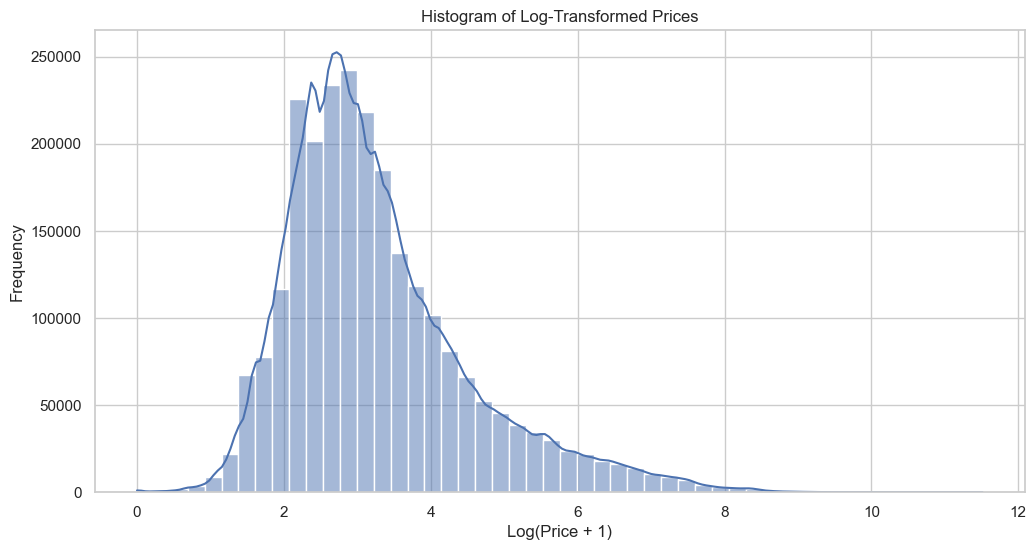

In [100]:
# log-histogram to allow all data 

sns.histplot(np.log1p(num.price), bins=50, kde=True)
plt.title("Histogram of Log-Transformed Prices")
plt.xlabel("Log(Price + 1)")
plt.ylabel("Frequency")
plt.show()


Based on the boxplot, we can see that the real outliers are starting somewhere at the price of 20000. Let's see, which products are coming with these high prices:

In [101]:
high_priced_products = df.loc[num.price > 20000, ["title", "price"]]

display(high_priced_products)

,title,price
319555,HEDUSA Halloween 3D Holographic Fan 3D Hologra...,22933.42
1408966,BM4445-FI1-01200R10-03-E03 Driver,23482.73
1430208,Equipment Home Gym Foldable Rowing Machines Ro...,20489.75
1430241,Equipment Home Gym Foldable Rowing Machines Ro...,20015.45
1490285,YXHUI Kids Girls Figure Skating Dress Long Sle...,21999.00
1490286,YXHUI Kids Girls Figure Skating Dress Long Sle...,21999.00
1758235,APC Micro DC 42U SX 5KVA 230V,20216.00
1905315,Abaodam decor christmas ornaments Desk Ornamen...,24674.59
1907271,Outdoor Furniture Wood Porch Swing Black Brown...,21464.82
1907272,Outdoor Furniture Wood Porch Swing Black Brown...,21464.82


**Business Answer:**

An analysis of 2,443,651 product listings on Amazon UK reveals a highly uneven price distribution with a strong concentration of low-priced products and a small number of extremely high-priced outliers.

The typical product price is around 10–20 pounds, with 9.99 pounds beind the most frequent one. The much higher average price (than median and mode) indicates that a small number of very expensive items skew the overall average upward.
Outlier analysis shows that prices above ~50 pounds appear as statistical outliers, thoug values above 20 000 pounds are rare (only 13 items), but spanning until 100 000 pounds.
Due to this skew, logartithmic scale were required for meaningful boxplots and histograms, emphasizing the extreme gap between the bulk of affordable products and a handful of high-valued items.


## Part 3: Data Interpretation

**Business Question:** How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

### 3.1 Measures of Centrality:

- Calculate the mean, median, and mode for the rating of products.
- How do customers generally rate products? Is there a common trend?

In [49]:
# mean rating

num.stars.mean()

2.152836472966065

In [50]:
# median rating

num.stars.median()

0.0

In [51]:
# mode rating

num.stars.mode()

0    0.0
Name: stars, dtype: float64

It seems that the average (mean) rating is at around ~2, but the most common ratings are at 0 stars (median + mode). The question however is, whether or not no rating is counted as 0 given stars, which represents then simply an unreviewed item. 

Let's crosscheck with the reviews:

In [ ]:
non_rev_items = df.loc[num.stars == 0, ["reviews", "stars"]].sum()

display(non_rev_items)

reviews    0.0
stars      0.0
dtype: float64

The non-reviewed items are directly correlating with 0 given stars. No star == no review. Means, we can see this set of data as not important for the further analysis. 

In [59]:
# mean of stars of reviewed items

df.loc[df['reviews'] != 0, 'stars'].mean()

4.31916076222691

In [60]:
# median of stars of reviewed items

df.loc[df['reviews'] != 0, 'stars'].median()

4.4

In [61]:
# mean of stars of reviewed items

df.loc[df['reviews'] != 0, 'stars'].mode()

0    4.5
Name: stars, dtype: float64

So if we only look at the reviewed items, the amount of stars given is actually pretty high and mean, mode, and median are pretty close (around 4.4 stars).

### 3.2 Measures of Dispersion:

- Determine the variance, standard deviation, and interquartile range for product rating.
- Are the ratings consistent, or is there a wide variation in customer feedback?

In [65]:
# all data - 0 reviews

df.loc[df['reviews'] != 0, 'stars'].describe().round(1)

count    1218010.0
mean           4.3
std            0.6
min            1.0
25%            4.1
50%            4.4
75%            4.6
max            5.0
Name: stars, dtype: float64

In [69]:
df.loc[df['reviews'] != 0, 'stars'].var()


0.3083433752380519

Interpretation:

- mean: 4.3, std: 0.6, iqr = 0.5
- most customers rate between 4.1 – 4.6 -> fairly consistent
- very few under 3 stars ratings

-> ratings are relatively consistent; customer feedback doesn't vary widely



### 3.3 Shape of the Distribution:

- Calculate the skewness and kurtosis for the rating column.
- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [82]:
df.loc[df['reviews'] != 0, 'stars'].skew()

-2.3795681122127945

In [84]:
df.loc[df['reviews'] != 0, 'stars'].kurt()

9.78193769066435

- non-normal distribution
- highly skewed 
- leaning towards higher values
- negativ skewer 

- leptokurtic distribution 
- values are near the mean & pretty close to high extreme 

### 3.4 Visualizations:

- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

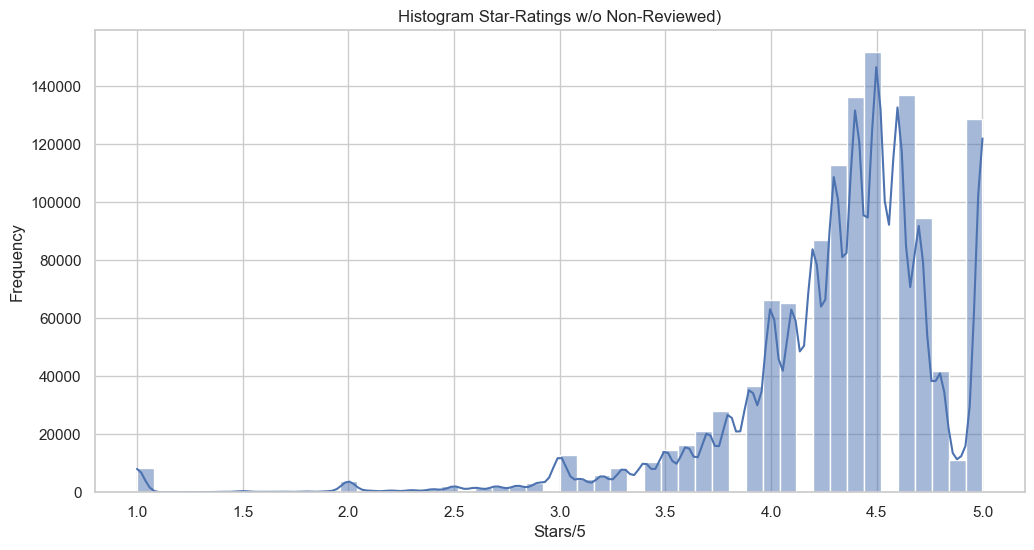

In [ ]:
# rating distribution via histogram

sns.histplot(df.loc[df['reviews'] != 0, 'stars'], bins=50, kde=True)
plt.title("Histogram Star-Ratings w/o Non-Reviewed")
plt.xlabel("Stars (1–5)")
plt.ylabel("Frequency")
plt.show()

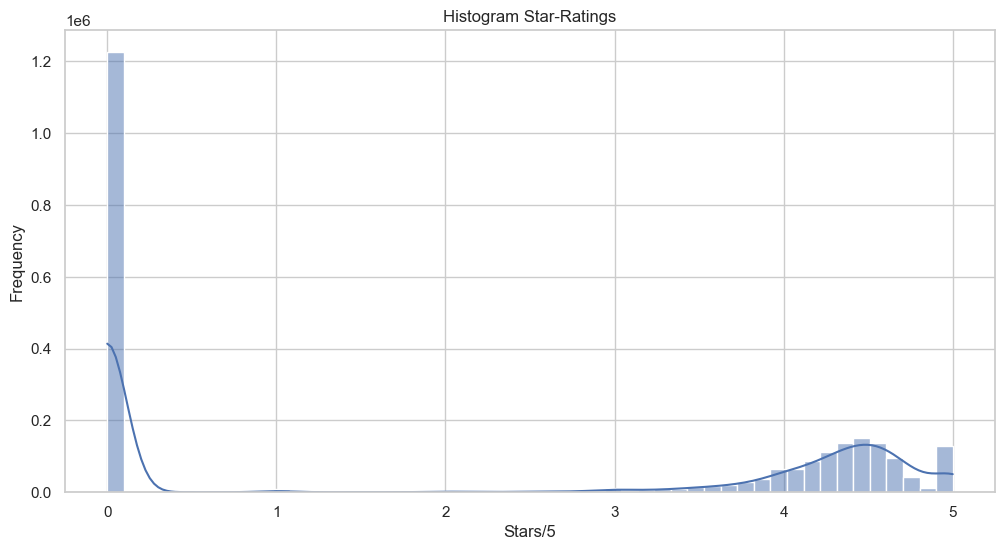

In [ ]:
# rating distribution via histogram

sns.histplot(num.stars, bins=51, kde=True)
plt.title("Histogram Star-Ratings (including non-reviewed items)")
plt.xlabel("Stars (0–5)")
plt.ylabel("Frequency")
plt.show()

**Business Answer:**
An analysis of 1,218,010 product ratings (excluding items without reviews) reveals that customer feedback on Amazon UK is overwhelmingly positive and highly consistent across products.

The average rating of 4.3 indicates a generally high level of customer satisfaction. The median of 4.4 and mode of 4.5 are confirming this.
The negative skew (-2.4) shows a concentration towrds the high end (4-5 stars rating), with relatively few low ratings. Which is also visible in the histogram. 
